# Case set up
### Import libraries

In [1]:
import os
import sys
import copy
import importlib
import joblib as jl
import numpy as np
import tensorflow as tf

from tqdm import tqdm
from matplotlib import pyplot as plt

### Define PrODE and working case directories paths

In [2]:
prode_dir = os.path.normpath(os.environ['WORKSPACE_PATH'] + '/ML/PrODE/prode/')
working_dir = "./"

In [3]:
if importlib.util.find_spec('prode') is None:
    sys.path.append(prode_dir)
sys.path.append(working_dir)

### Import additional libraries

In [4]:
# PrODE -----------------------------------------------------------------------
from prode.utilities import utils
from prode.apps import functionObjects as fun
from prode.postprocessing import testing, training

# Extra modules ---------------------------------------------------------------
# Inputs
import inputs
# Physics-related
from physics.data_generator import DataGenerator
from prode.physics.general import const
from prode.physics.thermochemistry import specie as specieMdl
from prode.physics.thermochemistry.reactionThermo import mixture as mixMdl

### Initialize network

In [5]:
net = fun._net(
    input_module=inputs
)


[PrODE]: Initializing 'IsoThermChemReacNN' network ...


### Initialize PrODE model

In [6]:
from inputs.general import flags

for k in ('train', 'save'):
    flags[k] = 0
if flags['load'] not in (1, 2):
    utils.raise_value_err(
        "The network has to be restored from a saved or a checkpointed "
        "one. Modified the 'load' entry in the `flags` input variable."
    )
model = fun._model(
    flags=flags,
    input_module=inputs,
    net=net
)


[PrODE]: Building 'IsoThermChemReacNN' network ...
Model: "IsoThermChemReact_MMOpNN"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 29)]         0                                            
__________________________________________________________________________________________________
input_2 (InputLayer)            [(None, 1)]          0                                            
__________________________________________________________________________________________________
branch_fn (Lambda)              (None, 29)           0           input_1[0][0]                    
__________________________________________________________________________________________________
trunk_fn (Scaling)              (None, 1)            2           input_2[0][0]                    
_______________________

### Generate testing data

In [7]:
# Generate Testing Data ---------------------------------------------------
dataGen_args = utils.get_args_values(
    args=utils.get_args(DataGenerator.__init__),
    modules=[inputs.data, inputs.general]
)
dataGen = DataGenerator(
    **dataGen_args
)
dataGen.data_dir = "./data/"
if not os.path.exists(dataGen.data_dir):
    os.makedirs(dataGen.data_dir)

utils.print_main("Generating testing pts ...")
if inputs.data.from_file:
    test_data = dataGen.testing_data(
        inputs.data.file['test'],
        header=inputs.data.header
    )
else:
    raise NotImplementedError

  0%|          | 0/100 [00:00<?, ?it/s]


[PrODE]: Generating testing pts ...


100%|██████████| 100/100 [01:58<00:00,  1.18s/it]


# Postprocessing - Model analysis

## Set up analysis

In [8]:
path = './model_analysis/'
if not os.path.exists(path):
    os.makedirs(path)
    
FLAGS = {
    'pred': 0,
    'one_pass': 0,
    'speedup': 0,
    'recursive': 0,
    'noneq': 0,
    'levels': 0
}

#### Get predictions

In [9]:
if FLAGS['pred']:
    utils.print_main("Postprocessing physical quantities ...")
    x, y, y_pred = [], [], []
    for scenario in tqdm(test_data):
        x_i, y_i = scenario
        x.append(x_i)
        y.append(y_i)
        y_pred.append(model.net.predict(x_i))
    n = len(test_data)

## One-pass inference
Setting up

In [10]:
path_ = path + '/onePassInference/'
if not os.path.exists(path_):
    os.makedirs(path_)

ts_label = {}
for i, name in enumerate(inputs.network.names):
    d = 1 if i == 0 else inputs.general.dim['out'][i]
    ts_label[name] = [r'$O$'] \
        + [r'$O_2^{({%s},{%s})}$' % (i+1,j+1) for j in range(d)]

In [11]:
def output_ops(y, timescale):
    if timescale == 0:
        return tf.reverse(y[0], axis=[1])
    else:
        return tf.concat([y[0][:,1:2], y[timescale]], 1)

def single_scenario(path, i):
    path_case = path_+'/case_'+str(i+1).zfill(3)
    for y_scale in ('linear', 'log'):
        path_y = path_case+'/'+y_scale
        if not os.path.exists(path_y):
            os.makedirs(path_y)
        for j, name in enumerate(inputs.network.names):
            x_ = x[i][-1]
            y_ = output_ops(y[i], j)
            y_pred_ = output_ops(y_pred[i], j)
            testing.plot_test(
                path_y,
                x_,
                y_,
                y_pred_,
                ts_label[name],
                fig_name=name,
                labels=[r'$t$ [s]', r'$Y$'],
                scales=['log', y_scale]
            )

if FLAGS['one_pass']:
    utils.print_submain("Testing 'one-pass' inference")
    out = jl.Parallel(n_jobs=-1)(
        jl.delayed(single_scenario)(path_, i) for i in tqdm(range(n))
    )


## Speedup
Setting up

In [12]:
path_ = path + '/speedup/'
if not os.path.exists(path_):
    os.makedirs(path_)

t_end = 1.e-7
num_ics = [int(10**i) for i in range(5)]
labels = ['DeepONet', 'Numerical Solver']

In [13]:
path_ = path + '/speedup/'

import time

if FLAGS['speedup']:
    utils.print_submain("Plotting execution time")

    # ODE solver
    dataGen.ODE_sol.t_end = t_end
    test_data = dataGen.testing_data(
        inputs.data.file['test'],
        exec_time=True,
        header=inputs.data.header
    )
    exec_time = []
    for scenario in test_data:
        exec_time.append(scenario[-1])
    ode_time_ref = np.mean(np.array(exec_time))

    # DeepONet & comparison
    exec_time = []
    for n in tqdm(num_ics):
        x_ = [i[np.random.choice(i.shape[0], n, replace=True)] for i in x[-1]]
        start = time.time()
        y_pred = model.net.predict(x_)
#         y_pred = model.net.call(x_)
        end = time.time()
        nn_time = end - start
        ode_time = ode_time_ref * n
        exec_time.append(np.array([nn_time, ode_time]))
    exec_time = np.vstack(exec_time)
    speedup = exec_time[:,1] / exec_time[:,0]

    # Plot style
    style = dict(
        marker='s',
        fillstyle='full',
        markersize=5,
        ls='--',
        lw=1.5
    )

    # Plot execution times
    fig = plt.figure()
    plt.xlabel('\# ODEs solved')
    plt.ylabel('Time [s]')
    plt.loglog(num_ics, exec_time, label=labels,**style)
    plt.legend(fontsize=16)
    plt.show()
    fig.savefig(path_ + 'times.pdf')
    plt.close()

    # Plot speedup
    fig = plt.figure()
    plt.xlabel('\# ODEs solved')
    plt.ylabel('Speedup')
    plt.semilogx(num_ics, speedup, **style)
    fig.savefig(path_ + 'speedup.pdf')
    plt.show()
    plt.close()

## Recursive inference
Setting up

In [14]:
path_ = path + '/recursiveInference/'
if not os.path.exists(path_):
    os.makedirs(path_)

ts_label = {}
for i, name in enumerate(inputs.network.names):
    d = 1 if i == 0 else inputs.general.dim['out'][i]
    ts_label[name] = [r'$O$'] \
        + [r'$O_2^{({%s},{%s})}$' % (i+1,j+1) for j in range(d)]

Recursive inference solver

In [15]:
def recursive_inference(
    ic,
    dt0=1.e-7,
    t_end=1.e-3,
    dt_str=1.4,
    dt_max=1.e-4
):
    # Initialize variables
    T = np.array([[0.]])
    Y = tf.concat(
        [1. - np.sum(ic[0:1,2:], keepdims=True), ic[0:1,2:]], axis=1
    )
    # Initialize loop
    t = T
    dt = dt0
    while t <= t_end:
        # Update inputs
        ic_ = np.expand_dims(tf.concat([ic[0,:2], Y[-1,1:]], axis=0), axis=0)
        t_ = np.array([[dt]])
        # Predictions
        y = output_ops(model.net([ic_,t_]), timescale=3)
        # Update time step
        t = t + dt
        dt = min(dt*dt_str, dt_max)
        # Collect data
        T = np.vstack((T, t))
        Y = np.vstack((Y, y))
    return T, Y

Recursive inference plotter

In [16]:
def plot_recursive_inference(
    path,
    x,
    y,
    x_pred,
    y_pred,
    var_names=None,
    fig_name=None,
    labels=[None, None],
    scales=['log', 'linear'],
    xlim=None,
    ylim=None
):
    fig = plt.figure()

    # Set up figure
    x_label, y_label = labels
    x_scale, y_scale = scales

    # X axis
    if x_label is not None:
        plt.xlabel(x_label)
    if x_scale is not None:
        plt.xscale(x_scale)
    if xlim is not None:
        plt.xlim(xlim)
    else:
        plt.xlim([min(x_pred), max(x_pred)])

    # Y axis
    if y_label is not None:
        plt.ylabel(y_label)
    if y_scale == 'log':
        plt.yscale(y_scale)
        if ylim is None:
            plt.ylim([np.amin(y)*5.e-1, np.amax(y)*5.e+0])
    else:
        delta = np.amax(y)*0.1
        if ylim is None:
            plt.ylim([np.amin(y)-delta, np.amax(y)+delta])
    if ylim is not None:
        plt.ylim(ylim)

    if len(y.shape) < 2:
        y = np.expand_dims(y, 1)

    # Plot figure
    # Define styles
    true_style = dict(
        lw=1.
    )
    pred_style = dict(
        marker='x',
        fillstyle='none',
        markersize=5,
        ls='',
        lw=1.
    )

    # Define parameters
    colors = []
    n = y.shape[1]

    # Loop over features
    for d in range(n):

        # >> Plot true values
        plt.plot(
            x,
            y[:,d],
            **true_style
        )
        colors.append(plt.gca().lines[-1].get_color())

        # >> Plot predicted values
        plt.plot(
            x_pred,
            y_pred[:,d],
            **pred_style,
            label=var_names[d],
            c=colors[-1]
        )

    # Plot color legends
    if n > 12:
        fs = 'x-small'
    elif n > 6:
        fs = 'small'
    else:
        fs = 'medium'
    plt.legend(
        [plt.plot([], [], c=colors[i])[0] for i in range(len(var_names))],
        var_names,
        fontsize=fs,
        ncol=int(np.ceil(n/3))
    )

    # Save figure
    fig_path = path + '/' + fig_name + '.pdf'
    fig.savefig(fig_path)
    plt.close()

In [17]:
if FLAGS['recursive']:
    utils.print_submain("Testing 'recursive' inference")
    for i in tqdm(range(n)):
        # Get solution
        t_ = x[i][1]
        y_ = output_ops(y[i], timescale=-1)
        t_pred_, y_pred_ = recursive_inference(x[i][0])
        # Plot solution
        path_case = path_+'/case_'+str(i+1).zfill(3)
        if not os.path.exists(path_case):
            os.makedirs(path_case)
        for y_scale in ('linear', 'log'):
            plot_recursive_inference(
                path_case,
                t_,
                y_,
                t_pred_,
                y_pred_,
                list(ts_label.values())[-1],
                fig_name=y_scale,
                labels=[r'$t$ [s]', r'$Y$'],
                scales=['log', y_scale],
                xlim=[1.e-8, 1.e-3]
            )

## Nonequilibrium distance
A linear form for the distribution function, which results in a thermalized local Boltzmann distribution within individual bins, has been employed.

This function is defined as follows
\begin{equation*}
    \mathcal{F}_i\left(\epsilon_s\right):\qquad\log\left(\frac{g_s}{n_s}\right)=\alpha_i+\beta_i\epsilon_s
    \quad\forall s\in\mathcal{I}_i
\end{equation*}
where
\begin{align}
    \alpha_i&=\log\left(\frac{Q_i}{n_i}\right)\label{eq:alpha}\\
    \beta_i&=\frac{1}{k_BT_i}\nonumber\\
    n_i&=Y_i\frac{\rho}{m}\nonumber
\end{align}

Setting up

In [18]:
path_ = path + '/noneq/'
if not os.path.exists(path_):
    os.makedirs(path_)

# Associate Timescale to grouping
ts_to_grouping = {
    'TS1': 'RVE1',
    'TS2': 'RVE3',
    'TS3': 'RVE9',
    'TS4': 'RVE27'
}

Species thermodynamics

In [19]:
def get_species_thermos(
    ts_to_grouping,
    species
):
    ts_to_species_thermos = {}
    for timescale, grouping in ts_to_grouping.items():
        # Update O2 with the proper grouping strategy
        species['O2']['rovib']['grouping'] = grouping
        # Initialize species thermodynamics
        spTh = {
            name: specieMdl.specieThermos.SpecieThermos(
                name,
                info,
                thermo='CoupledEnergyModes',
                EOS='PerfectGas',
            ) for name, info in species.items()
        }
        # Add species thermodynamics to the corresponding timescale
        ts_to_species_thermos[timescale] = spTh
    return ts_to_species_thermos

def update_partition_functions(
    ts_to_species_thermos,
    T
):
    Q = []
    for ts, species_thermos in ts_to_species_thermos.items():
        # Update species thermodynamics
        for spTh in species_thermos.values():
            spTh.intPF.update(T)
        # Get internal partition function
        Q.append(species_thermos['O2'].intPF.Q)
    return Q

# Get species thermodynamics
ts_to_species_thermos = get_species_thermos(
    ts_to_grouping,
    inputs.general.species
)

### Nonequilibrium distance definition: OPTION 1
Offset $\alpha$ from Maximum Entropy Principle reconstruction
\begin{align*}
    \alpha_i&=\log\left(\frac{Q_i}{n_i}\right)\\
    &=\log\left(\frac{Q_i}{Y_i}\frac{m}{\rho}\right)
\end{align*}

In [20]:
def eval_alpha(rho, Y, Q):
    return tf.nest.map_structure(
        lambda q, y: np.log((q/y)*(2*const.mass['O']/rho)), Q, Y
    )

def get_alpha(data):
    # Extract data
    (ic, t), Y = data

    # Get temperature and density from initial condition
    T = np.take(ic, [0], axis=1)
    rho = np.take(ic, [1], axis=1)

    # Update partition functions with the temperature of the physical scenario
    Q = update_partition_functions(ts_to_species_thermos, T)

    # Extract only O2 mass fraction from Timescale 1
    Y[0] = np.take(Y[0], [0], axis=1)
    
    return t, eval_alpha(rho, Y, Q)

Nonequilibrium distance calculated as norm $\left(p=1\right)$ of the differential offset
* TS$^{(3)}$-to-TS$^{(4)}$
\begin{equation*}
    \epsilon_i^{(3-4)} = \sum_{j,\mathcal{I}_j^{(4)}\in\mathcal{I}_i^{(3)}}
    \left\lVert\alpha_i^{(3)}-\alpha_j^{(4)}\right\rVert_p
    \quad\forall\mathcal{I}_i^{(3)}\in\text{RVE}_9
\end{equation*}
* TS$^{(2)}$-to-TS$^{(4)}$
\begin{equation*}
    \epsilon_i^{(2-4)} = \sum_{j,\mathcal{I}_j^{(4)}\in\mathcal{I}_i^{(2)}}
    \left\lVert\alpha_i^{(2)}-\alpha_j^{(4)}\right\rVert_p
    \quad\forall\mathcal{I}_i^{(2)}\in\text{RVE}_3
\end{equation*}
* TS$^{(1)}$-to-TS$^{(4)}$
\begin{equation*}
    \epsilon_1^{(1-4)} = \sum_{j,\mathcal{I}_j^{(4)}\in\mathcal{I}_1^{(1)}}
    \left\lVert\alpha_1^{(1)}-\alpha_j^{(4)}\right\rVert_p
    \quad\mathcal{I}_1^{(1)}\in\text{RVE}_1
\end{equation*}

In [21]:
def eval_dalpha_norm(alpha, norm_order=2):
    dalpha_norm = []
    for ts, alpha_ts in enumerate(alpha):
        dalpha_norm_ts = []
        if ts == len(alpha)-1:
            continue
        indeces = model.net.ts_fast_conn[ts]
        for i, idx in enumerate(indeces):
            alpha_fast = np.take(alpha[-1], idx, axis=1)
            alpha_slow = np.take(alpha_ts, [i], axis=1)
            norm = tf.norm(
                alpha_slow - alpha_fast, ord=norm_order, axis=1, keepdims=True
            )
            dalpha_norm_ts.append(norm)
        dalpha_norm.append(tf.concat(dalpha_norm_ts, axis=1))
    return dalpha_norm

In [22]:
i = np.random.randint(0, 100)
# i = 0
o = 2
data = copy.deepcopy(test_data[i])
t, alpha = get_alpha(data)
noneq_dist = eval_dalpha_norm(alpha, norm_order=o)

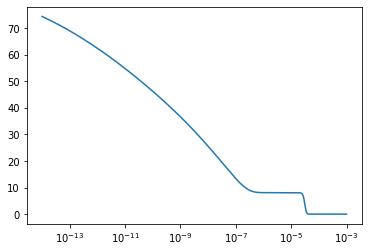

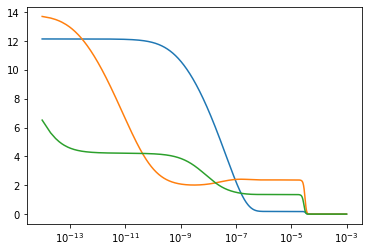

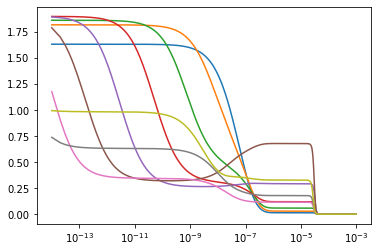

In [23]:
for ned in noneq_dist:
    fig = plt.figure()
    plt.semilogx(t, ned)

## Levels distribution
Setting up

In [24]:
path_ = path + '/levelsDist/'
if not os.path.exists(path_):
    os.makedirs(path_)

# ts_label = {}
# for i, name in enumerate(inputs.network.names):
#     d = 1 if i == 0 else inputs.general.dim['out'][i]
#     ts_label[name] = [r'$O$'] \
#         + [r'$O_2^{({%s},{%s})}$' % (i+1,j+1) for j in range(d)]

# Get reactive mixture thermodynamics
ts_to_mixture = {}
for ts, species_thermos in ts_to_species_thermos.items():
    ts_to_mixture[ts] = mixMdl.multiComponent.MultiComponent(species_thermos)

Compute the levels distribution dynamics for each timescale

In [25]:
def get_ts_lev_dist(data):
    # Extract data
    (ic, t), Y = data

    # Get temperature and density from initial condition
    T = np.take(ic, [0], axis=1)
    rho = np.take(ic, [1], axis=1)

    # Extract O and O2 mass fraction from Timescale 1
    Y_O = np.take(Y[0], [1], axis=1)
    Y[0] = np.take(Y[0], [0], axis=1)

    # Loop over the various timescale mixtures
    TS = []
    mix = dict(O=Y_O)
    for i, (ts, mix_ts) in enumerate(ts_to_mixture.items()):
        mix['O2'] = Y[i]
        # Update the mixture with the new mass fractions
        mix_ts.update(mix)
        mix_ts.n_(rho=rho)
        # Update the partition functions
        for spTh in mix_ts.spTh.values():
            spTh.intPF.update(T)
        # Get n, g, E levels for each bin
        TS.append(
            mix_ts.spTh['O2'].intPF.levels_distribution()
        )
    return t, TS

Coarse-grained states number density plotter

In [26]:
def plot_levels(
    path=None,
    lev_dist=None,
    var_names=None,
    title=None,
    labels=[r'$\epsilon_i$ [eV]', r'$n_i\//\/g_i$ [m$^{-3}$]'],
    scales=['linear', 'log'],
    xlim=None,
    ylim=None
):
    fig = plt.figure()

    if title is not None:
        plt.title(title)

    x_label, y_label = labels
    x_scale, y_scale = scales

    # X axis
    if x_label is not None:
        plt.xlabel(x_label)
    if x_scale is not None:
        plt.xscale(x_scale)
    if xlim is not None:
        plt.xlim(xlim)

    # Y axis
    if y_label is not None:
        plt.ylabel(y_label)
    if x_scale is not None:
        plt.yscale(y_scale)
    if ylim is not None:
        plt.ylim(ylim)

    # Plotting
    style = dict(
        lw=1,
        marker='o',
        fillstyle='none',
        markersize=0.5,
        linestyle='none'
    )
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    
    # Loop over Timescales
    for i, (n, g, E) in enumerate(lev_dist):
        # Loop over bins
        for b in range(len(n)):
            plt.plot(E[b], n[b]/g[b], c=colors[i], **style)
                
#     TS = tf.nest.flatten(TS)
#     colors = [None]*len(TS)
#     # Loop over Timescales
#     for i, (n, g, E) in enumerate(TS):
#         style.pop('c')
#         # Loop over bins
#         for b in range(len(n)):
#             if colors[i] is not None:
#                 style['c'] = colors[i]
#             plt.plot(E[b], n[b]/g[b], **style)
#             if colors[i] is None:
#                 colors[i] = plt.gca().lines[-1].get_color()

    plt.legend(
        [plt.plot([], [], c=colors[i])[0] for i in range(len(var_names))],
        var_names
    )

    fig.savefig(path)
    plt.close()
    

In [27]:
i = np.random.randint(0, 100)
# i = 0
o = 2
data = copy.deepcopy(test_data[i])
t, TS = get_ts_lev_dist(data)


In [29]:
tf.nest.map_structure(lambda x:x.shape,TS)

[([TensorShape([1418, 6115])],
  [TensorShape([6115, 1])],
  [TensorShape([6115, 1])]),
 ([TensorShape([1418, 1440]),
   TensorShape([1418, 3697]),
   TensorShape([1418, 978])],
  [TensorShape([1440, 1]), TensorShape([3697, 1]), TensorShape([978, 1])],
  [TensorShape([1440, 1]), TensorShape([3697, 1]), TensorShape([978, 1])]),
 ([TensorShape([1418, 270]),
   TensorShape([1418, 492]),
   TensorShape([1418, 678]),
   TensorShape([1418, 895]),
   TensorShape([1418, 1196]),
   TensorShape([1418, 1606]),
   TensorShape([1418, 591]),
   TensorShape([1418, 280]),
   TensorShape([1418, 107])],
  [TensorShape([270, 1]),
   TensorShape([492, 1]),
   TensorShape([678, 1]),
   TensorShape([895, 1]),
   TensorShape([1196, 1]),
   TensorShape([1606, 1]),
   TensorShape([591, 1]),
   TensorShape([280, 1]),
   TensorShape([107, 1])],
  [TensorShape([270, 1]),
   TensorShape([492, 1]),
   TensorShape([678, 1]),
   TensorShape([895, 1]),
   TensorShape([1196, 1]),
   TensorShape([1606, 1]),
   TensorSha

In [28]:
# Plotting levels ---------------------------------------------------------
if FLAGS['levels']:
    utils.print_submain("Plotting levels distributions")
    
    
    
    
    for j, t_shot in enumerate(time_shots):
        idx = np.argmin(np.absolute(t - t_shot), axis=0)
                
                
    path_ = path + '/levels'
    if not os.path.exists(path_):
        os.makedirs(path_)

    mix = {}
    for gr in inp.postprocessing.groupings:
        species = inp.general.species 
        species['O2']['rovib']['grouping'] = gr
        spTh = {
            name: specieMdl.specieThermos.SpecieThermos(
                name,
                info,
                thermo='CoupledEnergyModes',
                EOS='PerfectGas',
            ) for name, info in species.items()
        }
            mix[gr] = mixMdl.multiComponent.MultiComponent(spTh)

        for i in tqdm(range(len(x))):
            path_test = path_+'/test_'+str(i+1)
            if not os.path.exists(path_test):
                os.makedirs(path_test)

                


                path_tshots = path_test + '/shot_' + str(j+1)
                if not os.path.exists(path_tshots):
                    os.makedirs(path_tshots)

                # Plot number densities
                plot_levels(
                    path_tshots+'/TS012.pdf',
                    TS,
                    inp.postprocessing.timescales,
                    title='t = %.2e s' % t[idx]
                )

#                 for k in range(len(TS)):
#                     plot_levels(
#                         path_tshots+'/TS'+str(k)+'.pdf',
#                         [TS[k]],
#                         inp.postprocessing.timescales[k],
#                         title='Bins population at t = %.3e s' % t[idx]
#                     )
#                     if k != 0:
#                         plot_levels(
#                             path_tshots+'/TS'+str(k-1)+str(k)+'.pdf',
#                             TS[k-1:k+1],
#                             inp.postprocessing.timescales[k-1:k+1],
#                             title='Bins population at t = %.3e s' % t[idx]
#                         )

IndentationError: unexpected indent (<ipython-input-28-dbc19352670a>, line 20)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

fig, ax = plt.subplots()
xdata, ydata = [], []
ln, = plt.plot([], [], 'ro')

def init():
    ax.set_xlim(0, 2*np.pi)
    ax.set_ylim(-1, 1)
    return ln,

def update(frame):
    xdata.append(frame)
    ydata.append(np.sin(frame))
    ln.set_data(xdata, ydata)
    return ln,

ani = FuncAnimation(fig, update, frames=np.linspace(0, 2*np.pi, 128),
                    init_func=init, blit=True)
# plt.show()



# import time

# u = f(x)

# fig = plt.figure(figsize=(8,8))
# plt.title('u vs x')
# line1, = plt.plot(x, u, lw=3, clip_on=False)
        
# def timestepper(n):
#     uex = f((x - c * (n+1) * dt) % 1.0)
#     line1.set_data(x, uex) 
#     return [line1]

# from matplotlib import animation
# from IPython.display import HTML
from IPython.display import HTML
# ani = animation.FuncAnimation(fig, timestepper, frames=nt, interval=20)
html = HTML(ani.to_jshtml())
plt.clf()
html

